# 05 — Horizonte: classificação antecipada (curva de desempenho por horizonte)

**Trabalho final — Tópicos Especiais em ESSC II (IA aplicada a Séries Temporais)**

O enunciado pede a **curva de erro do passo +1 ao +H**. No nosso problema não há valores futuros a prever: a pergunta equivalente é **quão cedo** dá para reconhecer a palavra. O "horizonte" vira a **fração observada do sinal**: o modelo decide vendo só os primeiros $h$ instantes da série, com $h \in \{4, 8, \dots, 32\}$, ou seja, de 12,5% a 100% do sinal.

Isso tem uso prático (um tradutor em tempo real que responde antes do sinal acabar) e é a forma de **classificação antecipada** (*early classification*) de séries temporais.

### As três estratégias (paralelo com Bontempi, notebook 02 da disciplina)

| Estratégia | Como funciona | Paralelo na previsão |
|---|---|---|
| **Sem adaptação** | o modelo treinado com a série inteira (100%) recebe só o começo dela | usar um modelo fora do regime para o qual foi treinado |
| **Direta** | **um modelo por horizonte**, cada um treinado só com os primeiros $h$ instantes | estratégia **direta** de Bontempi: um modelo especialista para cada passo $t+h$ |
| **Modelo único** | **um só modelo** treinado com prefixos de tamanho sorteado a cada lote (aumento por truncamento) | estratégia **MIMO / modelo compartilhado**: um modelo para todos os horizontes |

Assim como em Bontempi, a direta é a mais especializada e a mais cara (4 modelos por rodada), e o modelo único é o mais barato de manter.

### Causalidade

Em cada horizonte, a entrada contém **apenas** os instantes $1..h$, e nada do que vem depois entra no modelo. O z-score usa média e desvio do treino (vídeos de outras pessoas), e não do vídeo que está sendo classificado. As redes aceitam qualquer comprimento de entrada (`shape=(None, 321)`); o Random Forest, que precisa de um número fixo de colunas, só existe na estratégia direta.

**Limitação que precisa ser dita no artigo:** o eixo do tempo da série é o **trecho ativo** do sinal, reamostrado para 32 instantes (notebook 00). Para recortar esse trecho, o pipeline usa o vídeo inteiro (onde a mão sai e volta ao repouso). Então "25% do sinal" é 25% da **duração do sinal**, conhecida só no fim. Num sistema em tempo real, seria preciso detectar o início do sinal online e trabalhar com o tempo absoluto. O experimento mede **quanto da informação discriminativa está no começo do gesto**, que é a pergunta deste notebook.

**Modelos:** Random Forest (A), CNN-1D e WaveNet (B; a WaveNet é causal por construção) e GRU (C).

**Tempo:** ~1h30 com GPU (Colab T4 ou TensorFlow no WSL2); algumas horas só com CPU. O notebook grava cada treino e continua de onde parou.

## 1. Configuração

Se o Google Drive não montar (erro *credential propagation was unsuccessful*), a célula abre um botão para enviar o `minds_st.npz` direto do seu computador (`D:\ProjetoMestrado\trabalho_series_temporais\dados\`). Selecione **só esse arquivo**. Nesse caso, a última célula baixa os resultados num `.zip`.

In [1]:
import os, sys, time
from pathlib import Path
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score, log_loss

SEMENTES = [0, 1, 2]
RODADAS = [0, 1, 2, 3]
MAX_EPOCAS, PACIENCIA, LOTE = 200, 25, 32
H_AVALIAR = [4, 8, 12, 16, 20, 24, 28, 32]        # horizontes avaliados (instantes observados)
H_DIRETA = [8, 16, 24, 32]                        # horizontes com modelo próprio (25%, 50%, 75%, 100%)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
print("TensorFlow", tf.__version__, "| GPU:", [g.name for g in tf.config.list_physical_devices("GPU")] or "nenhuma (CPU)")

IN_COLAB = "google.colab" in sys.modules

DRIVE_OK = False
if IN_COLAB:
    from google.colab import drive
    try:
        drive.mount("/content/drive", force_remount=True)
        BASE = Path("/content/drive/MyDrive/trabalho_series_temporais")
        DRIVE_OK = True
    except Exception as e:
        print("AVISO: não consegui montar o Google Drive:", e)
        BASE = Path("/content/trabalho_series_temporais")
        print("Usando a pasta local do Colab:", BASE, "(baixe os resultados no fim: última célula)")
else:
    BASE = Path.cwd().parent if (Path.cwd().parent / "dados").exists() else Path.cwd()
DADOS, FIG, RES = BASE / "dados", BASE / "figuras", BASE / "resultados"
for p in (DADOS, FIG, RES):
    p.mkdir(parents=True, exist_ok=True)

if not (DADOS / "minds_st.npz").exists():
    if IN_COLAB:
        from google.colab import files
        print("Envie o arquivo minds_st.npz (selecione SÓ ele):")
        enviados = files.upload()
        nome = next((n for n in enviados if n.startswith("minds_st")), None)
        if nome is None:
            raise FileNotFoundError(f"Nenhum arquivo minds_st*.npz entre os enviados: {list(enviados)}")
        (DADOS / "minds_st.npz").write_bytes(enviados[nome])
        print("salvo:", DADOS / "minds_st.npz", f"({len(enviados[nome]) / 1e6:.1f} MB)")
    else:
        raise FileNotFoundError(f"Não achei {DADOS / 'minds_st.npz'} (rode o notebook 00).")

ARQ = RES / "05_horizonte_por_rodada.csv"        # uma linha por (estratégia, modelo, h_treino, h_avaliado, rodada, semente)
ESTRATEGIAS = ["Sem adaptação", "Direta", "Modelo único"]
MODELOS = ["Random Forest", "CNN-1D", "WaveNet", "GRU"]

def salvar_fig(nome):
    plt.savefig(FIG / f"05_{nome}.png", bbox_inches="tight", dpi=150)

d = np.load(DADOS / "minds_st.npz", allow_pickle=False)
X, y = d["X"], d["y"]
classes = d["classes"].astype(str)
sinalizante, grupo, VAL = d["sinalizante"], d["grupo"], d["validacao"]
N, T, F = X.shape
K = len(classes)

def particao(rodada):
    te = np.where(grupo == rodada)[0]
    va = np.where(np.isin(sinalizante, VAL[rodada]))[0]
    tr = np.setdiff1d(np.arange(N), np.concatenate([te, va]))
    return tr, va, te

def padronizar(X, tr):
    mu = X[tr].reshape(-1, X.shape[-1]).mean(0)
    sd = X[tr].reshape(-1, X.shape[-1]).std(0) + 1e-6
    return ((X - mu) / sd).astype(np.float32)

def metricas(y_true, y_pred):
    return dict(acuracia=accuracy_score(y_true, y_pred), acuracia_balanceada=balanced_accuracy_score(y_true, y_pred),
                f1_macro=f1_score(y_true, y_pred, average="macro"))
print(f"séries {N} | T={T} | F={F} | horizontes avaliados: {H_AVALIAR}")

I0000 00:00:1795447310.292243    8080 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1795447312.597446    8080 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


TensorFlow 2.21.0 | GPU: ['/physical_device:GPU:0']


séries 1158 | T=32 | F=321 | horizontes avaliados: [4, 8, 12, 16, 20, 24, 28, 32]


## 2. Modelos

As mesmas arquiteturas dos notebooks 02 e 03. Todas as redes aceitam entradas de qualquer comprimento:

- **CNN-1D:** convoluções com `padding="same"` (dentro do prefixo observado) e média global no tempo;
- **WaveNet:** convoluções causais dilatadas (1, 2, 4, 8, 16) e média global no tempo;
- **GRU:** duas camadas; a decisão vem do último estado, isto é, do último instante observado.

In [2]:
def entrada():
    x_in = keras.Input(shape=(None, F))
    return x_in, layers.GaussianNoise(0.1)(x_in)

def saida(x_in, h, nome):
    return keras.Model(x_in, layers.Dense(K, activation="softmax")(layers.Dropout(0.3)(h)), name=nome)

def cnn1d():
    x_in, h = entrada()
    for filtros, k in [(64, 5), (128, 5), (128, 3)]:
        h = layers.Activation("relu")(layers.BatchNormalization()(layers.Conv1D(filtros, k, padding="same")(h)))
    return saida(x_in, layers.GlobalAveragePooling1D()(h), "CNN-1D")

def wavenet(filtros=64, dilatacoes=(1, 2, 4, 8, 16)):
    x_in, h = entrada()
    h = layers.Conv1D(filtros, 1)(h)
    pulos = []
    for d_ in dilatacoes:
        f = layers.Conv1D(filtros, 2, dilation_rate=d_, padding="causal", activation="tanh")(h)
        g = layers.Conv1D(filtros, 2, dilation_rate=d_, padding="causal", activation="sigmoid")(h)
        z = layers.Multiply()([f, g])
        pulos.append(layers.Conv1D(filtros, 1)(z))
        h = layers.Add()([h, layers.Conv1D(filtros, 1)(z)])
    h = layers.Conv1D(filtros, 1, activation="relu")(layers.Activation("relu")(layers.Add()(pulos)))
    return saida(x_in, layers.GlobalAveragePooling1D()(h), "WaveNet")

def gru():
    x_in, h = entrada()
    h = layers.GRU(128, return_sequences=True)(h)
    return saida(x_in, layers.GRU(128)(h), "GRU")

REDES = {"CNN-1D": cnn1d, "WaveNet": wavenet, "GRU": gru}

def compilar(m):
    # jit_compile=False: sem a compilação XLA, que na GPU pelo WSL chegou a levar 7 minutos por modelo
    # (e o modelo único usa 8 comprimentos de entrada, o que dispararia uma compilação para cada um)
    m.compile(optimizer=keras.optimizers.Adam(1e-3), loss="sparse_categorical_crossentropy", metrics=["accuracy"],
              jit_compile=False)
    return m

## 3. Estratégia direta (e "sem adaptação")

Para cada horizonte $h \in \{8, 16, 24, 32\}$, um modelo é treinado e validado **só com os primeiros $h$ instantes** e avaliado no teste com os mesmos $h$ instantes.

O modelo de $h = 32$ (a série inteira) é o mesmo dos notebooks 02 e 03. Ele é também avaliado com **todos** os prefixos menores: essa é a estratégia **sem adaptação**, que não custa nenhum treino a mais.

In [3]:
res = pd.read_csv(ARQ) if ARQ.exists() else pd.DataFrame(columns=["estrategia", "modelo", "h_treino", "rodada", "semente"])
feitos = set(zip(res.estrategia, res.modelo, res.h_treino, res.rodada, res.semente))

def registrar(linhas):
    global res
    res = pd.concat([res, pd.DataFrame(linhas)], ignore_index=True)
    res.to_csv(ARQ, index=False)

for k in RODADAS:
    tr, va, te = particao(k)
    Z = padronizar(X, tr)
    for modelo in MODELOS:
        for h in H_DIRETA:
            for s in SEMENTES:
                if ("Direta", modelo, h, k, s) in feitos:
                    continue
                t_ini = time.time()
                if modelo == "Random Forest":
                    rf = RandomForestClassifier(n_estimators=500, max_features="sqrt", n_jobs=-1, random_state=s)
                    rf.fit(Z[tr, :h].reshape(len(tr), -1), y[tr])
                    pred = rf.predict(Z[te, :h].reshape(len(te), -1))
                    linhas = [dict(estrategia="Direta", modelo=modelo, h_treino=h, h_avaliado=h, rodada=k, semente=s,
                                   tempo_s=time.time() - t_ini, **metricas(y[te], pred))]
                else:
                    keras.utils.set_random_seed(s)
                    m = compilar(REDES[modelo]())
                    cb = [keras.callbacks.EarlyStopping(monitor="val_loss", patience=PACIENCIA, restore_best_weights=True),
                          keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=10, min_lr=1e-5)]
                    m.fit(Z[tr, :h], y[tr], validation_data=(Z[va, :h], y[va]), epochs=MAX_EPOCAS, batch_size=LOTE,
                          callbacks=cb, verbose=0)
                    t_treino = time.time() - t_ini
                    linhas = [dict(estrategia="Direta", modelo=modelo, h_treino=h, h_avaliado=h, rodada=k, semente=s,
                                   tempo_s=t_treino, **metricas(y[te], m.predict(Z[te, :h], verbose=0).argmax(1)))]
                    if h == T:                    # o modelo da série inteira também é avaliado com os prefixos menores
                        for ha in H_AVALIAR:
                            pred = m.predict(Z[te, :ha], verbose=0).argmax(1)
                            linhas.append(dict(estrategia="Sem adaptação", modelo=modelo, h_treino=T, h_avaliado=ha,
                                               rodada=k, semente=s, tempo_s=0.0, **metricas(y[te], pred)))
                    keras.backend.clear_session()
                registrar(linhas)
                print(f"rodada {k} | Direta | {modelo:13s} | h={h:2d} | semente {s} | F1 teste {linhas[0]['f1_macro']:.3f} "
                      f"| {linhas[0]['tempo_s']:.0f}s", flush=True)

## 4. Modelo único com prefixos aleatórios

Um só modelo por rodada e semente. A cada lote de treino, sorteia-se um comprimento $h \in \{4, 8, \dots, 32\}$ e todos os vídeos do lote são cortados nos primeiros $h$ instantes. Assim, o modelo aprende a decidir com qualquer quantidade de sinal observado.

O *early stopping* acompanha a **perda média na validação sobre os 8 horizontes**, para não favorecer só a série completa. Depois, o modelo é avaliado no teste em cada horizonte.

In [4]:
def lotes_com_prefixo(Z, y_, semente):
    # lotes de treino com comprimento sorteado (aumento por truncamento); a cada época, nova ordem e novos sorteios.
    # O tf.data declara o eixo do tempo como variável (None); o PyDataset do Keras fixava o tamanho do 1º lote.
    rng = np.random.default_rng(semente)
    def gerador():
        ordem = rng.permutation(len(y_))
        for i in range(0, len(y_), LOTE):
            idx = ordem[i:i + LOTE]
            h = int(rng.choice(H_AVALIAR))
            yield Z[idx, :h], y_[idx]
    return tf.data.Dataset.from_generator(gerador, output_signature=(
        tf.TensorSpec(shape=(None, None, F), dtype=tf.float32), tf.TensorSpec(shape=(None,), dtype=tf.int64)))

class PerdaMediaHorizontes(keras.callbacks.Callback):
    # grava em logs["val_media"] a perda de validação média sobre todos os horizontes (usada pelo early stopping)
    def __init__(self, Zva, yva):
        super().__init__()
        self.Zva, self.yva = Zva, yva
    def on_epoch_end(self, epoch, logs=None):
        perdas = [log_loss(self.yva, self.model.predict(self.Zva[:, :h], verbose=0), labels=range(K)) for h in H_AVALIAR]
        logs["val_media"] = float(np.mean(perdas))

for k in RODADAS:
    tr, va, te = particao(k)
    Z = padronizar(X, tr)
    for modelo in REDES:
        for s in SEMENTES:
            if ("Modelo único", modelo, T, k, s) in feitos:
                continue
            keras.utils.set_random_seed(s)
            m = compilar(REDES[modelo]())
            cb = [PerdaMediaHorizontes(Z[va], y[va]),
                  keras.callbacks.EarlyStopping(monitor="val_media", mode="min", patience=PACIENCIA, restore_best_weights=True),
                  keras.callbacks.ReduceLROnPlateau(monitor="val_media", mode="min", factor=0.5, patience=10, min_lr=1e-5)]
            t_ini = time.time()
            m.fit(lotes_com_prefixo(Z[tr], y[tr].astype(np.int64), s), epochs=MAX_EPOCAS, callbacks=cb, verbose=0)
            t_treino = time.time() - t_ini
            linhas = [dict(estrategia="Modelo único", modelo=modelo, h_treino=T, h_avaliado=ha, rodada=k, semente=s,
                           tempo_s=t_treino, **metricas(y[te], m.predict(Z[te, :ha], verbose=0).argmax(1))) for ha in H_AVALIAR]
            keras.backend.clear_session()
            registrar(linhas)
            print(f"rodada {k} | Modelo único | {modelo:8s} | semente {s} | F1 com 25%/50%/100%: "
                  f"{linhas[1]['f1_macro']:.3f} / {linhas[3]['f1_macro']:.3f} / {linhas[-1]['f1_macro']:.3f} | {t_treino:.0f}s", flush=True)
print("linhas gravadas:", len(pd.read_csv(ARQ)))

/home/magnusfelinto/venv_tf/lib/python3.10/site-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


/home/magnusfelinto/venv_tf/lib/python3.10/site-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


/home/magnusfelinto/venv_tf/lib/python3.10/site-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


/home/magnusfelinto/venv_tf/lib/python3.10/site-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


/home/magnusfelinto/venv_tf/lib/python3.10/site-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


/home/magnusfelinto/venv_tf/lib/python3.10/site-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


... (375 outputs left out)

/home/magnusfelinto/venv_tf/lib/python3.10/site-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


/home/magnusfelinto/venv_tf/lib/python3.10/site-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


rodada 3 | Modelo único | GRU      | semente 2 | F1 com 25%/50%/100%: 0.680 / 0.847 / 0.797 | 57s


linhas gravadas: 768


## 5. Curva de desempenho por horizonte

F1 macro no teste (pessoas nunca vistas) em função da fração do sinal observada. Média de 4 rodadas × 3 sementes; a faixa sombreada é ± 1 desvio padrão.

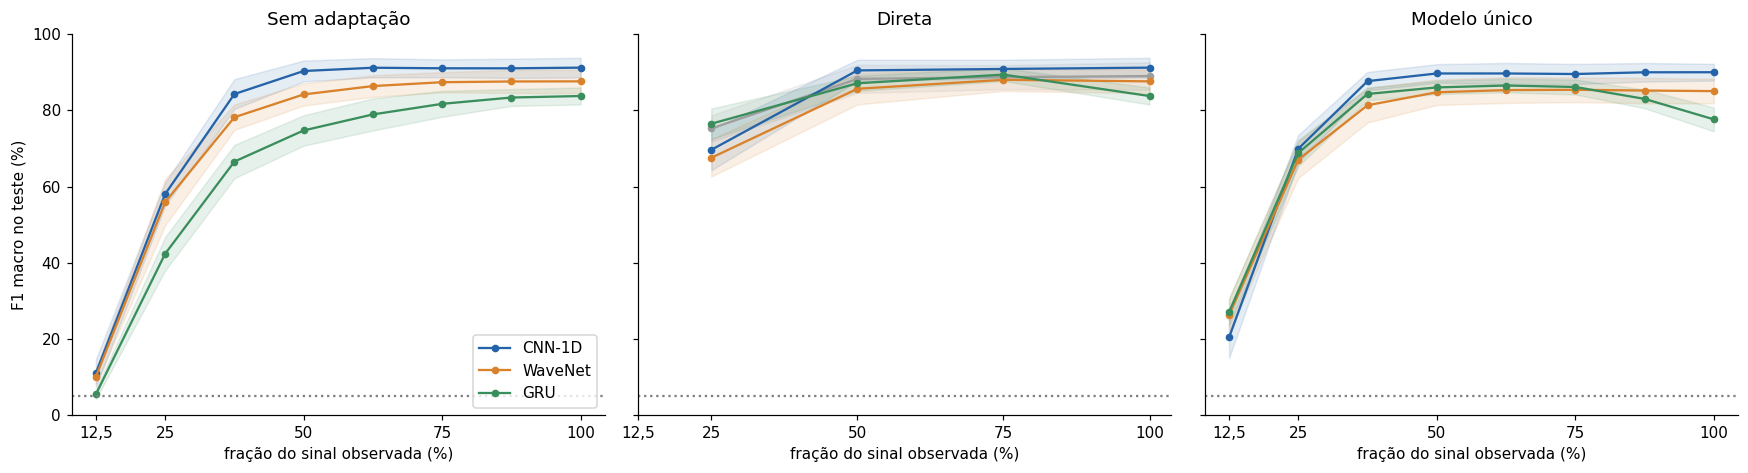

In [5]:
res = pd.read_csv(ARQ)
res["fracao"] = res.h_avaliado / T
cores = {"Random Forest": "#9e9e9e", "CNN-1D": "#2563A8", "WaveNet": "#D9822B", "GRU": "#3A8E5C"}
fig, axs = plt.subplots(1, 3, figsize=(16, 4.4), sharey=True)
for ax, est in zip(axs, ESTRATEGIAS):
    for modelo in MODELOS:
        r = res[(res.estrategia == est) & (res.modelo == modelo)]
        if r.empty:
            continue
        g = r.groupby("fracao").f1_macro.agg(["mean", "std"])
        ax.plot(100 * g.index, 100 * g["mean"], "o-", color=cores[modelo], label=modelo, ms=4)
        ax.fill_between(100 * g.index, 100 * (g["mean"] - g["std"]), 100 * (g["mean"] + g["std"]), color=cores[modelo], alpha=.12)
    ax.axhline(100 / K, ls=":", color="gray"); ax.set_title(est); ax.set_xlabel("fração do sinal observada (%)")
    ax.set_xticks([12.5, 25, 50, 75, 100], ["12,5", "25", "50", "75", "100"]); ax.set_ylim(0, 100)
axs[0].set_ylabel("F1 macro no teste (%)"); axs[0].legend(loc="lower right")
plt.tight_layout(); salvar_fig("curva_horizonte"); plt.show()

25%   50%   75%  100%
modelo        estrategia                           
Random Forest Direta         75.3  88.3  88.7  89.0
CNN-1D        Direta         69.6  90.5  90.9  91.2
              Modelo único   69.9  89.7  89.5  90.0
              Sem adaptação  58.0  90.3  91.0  91.2
WaveNet       Direta         67.6  85.7  88.0  87.6
              Modelo único   67.1  84.8  85.4  85.1
              Sem adaptação  55.9  84.2  87.4  87.6
GRU           Direta         76.5  87.1  89.4  83.8
              Modelo único   68.8  86.0  86.1  77.6
              Sem adaptação  42.4  74.7  81.7  83.8

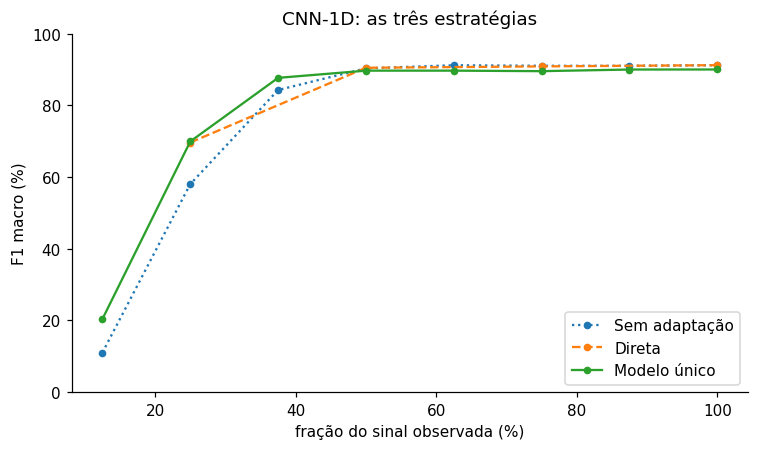

In [6]:
# tabela nos horizontes de 25%, 50%, 75% e 100%
tab = (res[res.h_avaliado.isin(H_DIRETA)].groupby(["modelo", "estrategia", "h_avaliado"]).f1_macro.mean()
       .unstack("h_avaliado").reindex(MODELOS, level=0))
tab.columns = [f"{int(100 * h / T)}%" for h in tab.columns]
display((100 * tab).round(1))
tab.to_csv(RES / "05_tabela_horizonte.csv")

# comparação das estratégias no melhor modelo
fig, ax = plt.subplots(figsize=(7, 4.2))
for est, ls in zip(ESTRATEGIAS, [":", "--", "-"]):
    g = res[(res.estrategia == est) & (res.modelo == "CNN-1D")].groupby("fracao").f1_macro.mean()
    ax.plot(100 * g.index, 100 * g, "o" + ls, label=est, ms=4)
ax.set_xlabel("fração do sinal observada (%)"); ax.set_ylabel("F1 macro (%)"); ax.set_ylim(0, 100)
ax.set_title("CNN-1D: as três estratégias"); ax.legend(); plt.tight_layout(); salvar_fig("estrategias_cnn"); plt.show()

### 5.1 Quanto do sinal é preciso?

Para cada modelo e estratégia: a menor fração observada em que o F1 chega a **90% do F1 final** (com o sinal inteiro). É uma medida de "precocidade" (*earliness*).

In [7]:
linhas = []
for (modelo, est), r in res.groupby(["modelo", "estrategia"]):
    g = r.groupby("h_avaliado").f1_macro.mean()
    alvo = 0.9 * g.loc[T]
    linhas.append(dict(modelo=modelo, estrategia=est, f1_final=100 * g.loc[T],
                       fracao_minima=f"{100 * g[g >= alvo].index.min() / T:.1f}%"))
display(pd.DataFrame(linhas).set_index(["modelo", "estrategia"]).round(1))

f1_final fracao_minima
modelo        estrategia                           
CNN-1D        Direta             91.2         50.0%
              Modelo único       90.0         37.5%
              Sem adaptação      91.2         37.5%
GRU           Direta             83.8         25.0%
              Modelo único       77.6         37.5%
              Sem adaptação      83.8         62.5%
Random Forest Direta             89.0         50.0%
WaveNet       Direta             87.6         50.0%
              Modelo único       85.1         37.5%
              Sem adaptação      87.6         50.0%

## 6. Síntese

**Resposta à pergunta do professor ("os modelos mantêm o desempenho com menos tempo de exposição do sinal?"):** sim, até a metade do sinal. Com **50% do trecho ativo** (~1,5 s), a CNN-1D já chega a **90,3–90,5% de F1**, praticamente o mesmo dos 91,2% com o sinal inteiro. Abaixo disso, o desempenho cai rápido: ~84–88% com 37,5%, 58–70% com 25% e quase o acaso com 12,5%.

| F1 macro (%) | 12,5% | 25% | 37,5% | 50% | 75% | 100% |
|---|---|---|---|---|---|---|
| CNN-1D, sem adaptação | 11,0 | 58,0 | 84,3 | 90,3 | 91,0 | 91,2 |
| CNN-1D, direta | — | 69,6 | — | 90,5 | 90,9 | 91,2 |
| CNN-1D, modelo único | 20,4 | 69,9 | 87,7 | 89,7 | 89,5 | 90,0 |
| Random Forest, direta | — | 75,3 | — | 88,3 | 88,7 | 89,0 |
| WaveNet, direta | — | 67,6 | — | 85,7 | 88,0 | 87,6 |
| GRU, sem adaptação | 5,5 | 42,4 | 66,6 | 74,7 | 81,7 | 83,8 |
| GRU, direta | — | 76,5 | — | 87,1 | **89,4** | 83,8 |
| GRU, modelo único | 27,1 | 68,8 | 84,3 | 86,0 | 86,1 | 77,6 |

*Média de 4 rodadas × 3 sementes, sinalizantes nunca vistos; desvios entre 2 e 6 pontos (tabela da seção 5).*

**1. A informação que distingue as palavras está na primeira metade do gesto.** Todas as curvas sobem forte entre 12,5% e 37,5% e ficam praticamente planas a partir de 50%. Como o repouso inicial foi cortado no pré-processamento (notebook 00), a primeira metade do trecho ativo já contém a configuração de mão, a locação e o começo do movimento. A segunda metade (o fim do movimento e a volta ao repouso) quase não acrescenta.

**2. Treinar para o horizonte (estratégia direta) só compensa nos horizontes curtos.** Com 25% do sinal, o modelo próprio supera o modelo treinado com a série inteira em **+11,6 pontos** na CNN-1D e na WaveNet e em **+34,1** na GRU (teste de Wilcoxon pareado, p ≤ 0,001). A partir de 50%, nas redes convolucionais, a diferença some (≤ 1,5 ponto, p > 0,2): a média global no tempo (GAP) torna essas redes naturalmente robustas a séries mais curtas. A GRU é a exceção: sem adaptação, ela perde 12,4 pontos com 50% e 7,7 com 75% (p < 0,001), porque o seu último estado foi treinado esperando o fim do gesto.

**3. O modelo único equivale à estratégia direta nas convoluções, com um modelo só.** Na CNN-1D, a diferença para a direta fica entre −1,3 e +0,3 ponto em todos os horizontes (sem significância). Na WaveNet, perde 2,6 pontos com 75% (p = 0,02). É o paralelo com Bontempi: a estratégia direta precisa de um modelo por horizonte (aqui, 4), e o modelo único atende todos os horizontes com um só, ao custo de um treino mais longo (na CNN-1D, ~205 s para o modelo único contra 4 × 28 s = 112 s para os quatro modelos diretos), porque a validação avalia os 8 horizontes a cada época. Na GRU, o modelo único é pior (−7,7 pontos com 25%, p = 0,001): a recorrência tem mais dificuldade em aprender bem todos os comprimentos ao mesmo tempo.

**4. A GRU acerta mais com 75% do que com 100% do sinal** (direta: 89,4% × 83,8%; modelo único: 86,1% × 77,6%). Como a decisão vem do último estado, a fase de **retração** (a mão voltando ao repouso, parecida em quase todas as palavras) "dilui" o que a rede lembrava do núcleo do sinal. Isso ajuda a explicar a desvantagem das recorrências no notebook 03 e sugere, para elas, *pooling* ou atenção sobre todos os estados, em vez do último.

**5. A causalidade da WaveNet não trouxe vantagem nos horizontes curtos** (67,6% com 25%, contra 69,6% da CNN-1D não causal). Quando a entrada já é só o prefixo, as duas veem a mesma informação. Nos horizontes curtos, os modelos mais simples se destacam: o Random Forest direto (75,3%) e a GRU direta (76,5%) são os melhores com 25% do sinal.

**6. Precocidade (seção 5.1).** A CNN-1D sem adaptação e com o modelo único chega a 90% do seu F1 final vendo só **37,5%** do sinal; a GRU direta, com 25%.

**Limitação (repetida da introdução):** "25% do sinal" é 25% da **duração do trecho ativo**, que foi recortado olhando o vídeo inteiro. Os resultados medem quanto da informação está no começo do gesto, e não a latência de um sistema em tempo real, que precisaria detectar o início do sinal sem ver o fim.


In [8]:
# Baixa os resultados quando o Drive não montou (a pasta /content é apagada quando o Colab desconecta)
if IN_COLAB and not DRIVE_OK:
    import shutil
    from google.colab import files
    shutil.make_archive("/content/resultados_05", "zip", str(BASE), "resultados")
    shutil.make_archive("/content/figuras_05", "zip", str(BASE), "figuras")
    files.download("/content/resultados_05.zip"); files.download("/content/figuras_05.zip")
else:
    print("resultados gravados em", RES)

resultados gravados em /mnt/d/ProjetoMestrado/trabalho_series_temporais/resultados
